# **Evaluación Parcial 2 – Deep Learning**
## **Clasificación de enfermedades en hojas de plantas mediante redes neuronales convolucionales (CNN)**
Asignatura: Deep Learning (DLY0100)  
Institución: Duoc UC  
Integrantes:

*   Betsabé Spring
*   Maria Aguirre


## **Introducción**
La identificación temprana de enfermedades en cultivos agrícolas es fundamental para prevenir pérdidas en la producción y favorecer el cuidado de las plantas. En este contexto, el Deep Learning ofrece herramientas que permiten automatizar el reconocimiento de patrones visuales mediante el análisis de imágenes.
El presente proyecto tiene como objetivo desarrollar y evaluar modelos de redes neuronales convolucionales (CNN) capaces de clasificar imágenes de hojas de tomate, papa y pimentón, identificando si se encuentran saludables o presentan alguna enfermedad.
Para ello, se utilizará el conjunto de datos PlantVillage, compuesto por imágenes organizadas en 15 clases correspondientes a diferentes condiciones de salud de las plantas.
Durante el desarrollo se realizarán etapas de exploración, preprocesamiento, entrenamiento y evaluación de los modelos, considerando métricas de rendimiento que permitan comparar sus resultados y analizar su capacidad de clasificación.


## **Objetivo general**
Desarrollar y comparar modelos de redes neuronales convolucionales para la clasificación automática de enfermedades en hojas de plantas, utilizando técnicas de Deep Learning y el dataset PlantVillage.

## **Objetivos específicos**
Explorar el conjunto de datos e identificar la distribución de imágenes entre las diferentes clases.
Preparar y preprocesar las imágenes para su utilización en modelos CNN.
Implementar y entrenar arquitecturas de redes neuronales convolucionales.
Evaluar el rendimiento de los modelos mediante métricas de clasificación.
Comparar los resultados obtenidos e identificar las fortalezas y limitaciones de las arquitecturas utilizadas.

## **1. Carga del conjunto de datos**
Para el desarrollo del proyecto se utilizará el conjunto de datos PlantVillage, que contiene imágenes de hojas de plantas clasificadas según su estado de salud y la presencia de enfermedades.
El dataset se encuentra almacenado en Google Drive en formato ZIP y será procesado mediante Google Colab, utilizando Python.
El procedimiento de carga contempla las siguientes etapas:  Conexión con Google Drive para acceder al archivo.

1.   Extraccion de las imagenes en el entorno temporal de Google Colab
2.   Verificacion de la estructura de las carpetas
3.   Identificacion de las clases disponibles

Tras realizar la carga, se identificaron 15 clases correspondientes a hojas de tomate, papa y pimentón, incluyendo categorías saludables y diferentes enfermedades.
Esta etapa permite verificar la disponibilidad de los datos antes de iniciar su análisis y preprocesamiento.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile
from tqdm.auto import tqdm

ruta_zip = "/content/drive/MyDrive/Prueba2_DeepLearning/PlantVillage.zip"
ruta_destino = "/content/PlantVillage"


os.makedirs(ruta_destino, exist_ok=True)
with zipfile.ZipFile(ruta_zip, "r") as zip_ref:

    archivos = zip_ref.infolist()

    print(f"Total de elementos: {len(archivos)}")

    for archivo in tqdm(archivos, desc="Descomprimiendo"):
        zip_ref.extract(archivo, ruta_destino)

print("Dataset descomprimido correctamente")
ruta_dataset = os.path.join(ruta_destino, "PlantVillage")

print("¿Existe el dataset?", os.path.isdir(ruta_dataset))
if os.path.isdir(ruta_dataset):
    print("Clases encontradas:")
    print(os.listdir(ruta_dataset))

Total de elementos: 20655


Descomprimiendo:   0%|          | 0/20655 [00:00<?, ?it/s]

Dataset descomprimido correctamente
¿Existe el dataset? True
Clases encontradas:
['Tomato_Spider_mites_Two_spotted_spider_mite', 'Potato___Late_blight', 'Tomato__Tomato_mosaic_virus', 'Tomato_Early_blight', 'Tomato_Septoria_leaf_spot', 'Pepper__bell___Bacterial_spot', 'Potato___Early_blight', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato_healthy', 'Tomato__Target_Spot', 'Tomato_Late_blight', 'Tomato_Bacterial_spot', 'Pepper__bell___healthy']


## **2. Análisis exploratorio del dataset (EDA)**
En esta etapa se analizará la estructura y distribución del conjunto de datos PlantVillage, compuesto por imágenes de hojas de tomate, papa y pimentón.
El dataset contiene 15 clases que representan diferentes enfermedades y estados saludables de las plantas.
El análisis exploratorio permitirá:


1.   Identificar la cantidad de imagenes disponibles por clase.
2.   Examinar la distribucion de las imagenes.
3.   Detectar posibles desbalances entre las categorias.
4.   Visualizar ejemplos de las imagenes utilizadas.


Esta información será fundamental para definir las estrategias de preprocesamiento y entrenamiento de los modelos CNN.

In [ ]:
import os
import pandas as pd

#ruta del dataset
ruta_dataset = "/content/PlantVillage/PlantVillage"
datos = []

for clase in sorted(os.listdir(ruta_dataset)):
    ruta_clase = os.path.join(ruta_dataset, clase)
    if os.path.isdir(ruta_clase):

        imagenes = [
            archivo for archivo in os.listdir(ruta_clase)
            if archivo.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        datos.append({
            "Clase": clase,
            "Cantidad de imágenes": len(imagenes)
        })

df_clases = pd.DataFrame(datos)
df_clases["Porcentaje (%)"] = (
    df_clases["Cantidad de imágenes"] /
    df_clases["Cantidad de imágenes"].sum() * 100
).round(2)

display(df_clases)
print("Total de imágenes:", df_clases["Cantidad de imágenes"].sum())
print("Total de clases:", len(df_clases))

,Clase,Cantidad de imágenes,Porcentaje (%)
0,Pepper__bell___Bacterial_spot,997,4.83
1,Pepper__bell___healthy,1478,7.16
2,Potato___Early_blight,1000,4.85
3,Potato___Late_blight,1000,4.85
4,Potato___healthy,152,0.74
5,Tomato_Bacterial_spot,2127,10.31
6,Tomato_Early_blight,1000,4.85
7,Tomato_Late_blight,1909,9.25
8,Tomato_Leaf_Mold,952,4.61
9,Tomato_Septoria_leaf_spot,1771,8.58


Total de imágenes: 20638
Total de clases: 15


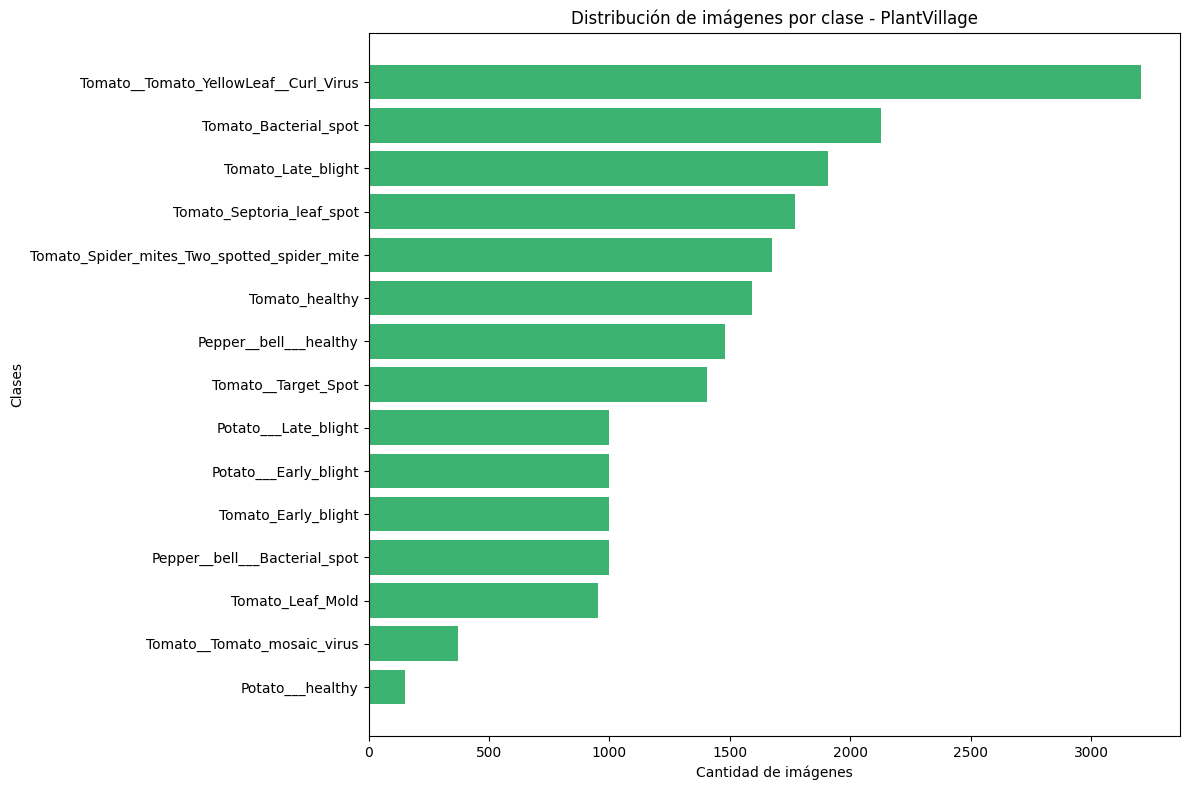

In [ ]:
import matplotlib.pyplot as plt

#orden de clases según la cantidad de imágenes
df_grafico = df_clases.sort_values(
    by="Cantidad de imágenes",
    ascending=True
)

plt.figure(figsize=(12, 8))
plt.barh(
    df_grafico["Clase"],
    df_grafico["Cantidad de imágenes"],
    color="mediumseagreen"
)

plt.title("Distribución de imágenes por clase - PlantVillage")
plt.xlabel("Cantidad de imágenes")
plt.ylabel("Clases")

plt.tight_layout()
plt.show()

El análisis exploratorio permitió identificar un total de 20.638 imágenes distribuidas en 15 clases, correspondientes a hojas de tomate, papa y pimentón.
Se observó que la distribución de imágenes no es uniforme entre las categorías, evidenciando un desbalance de clases.
La clase con mayor representación corresponde a Tomato Yellow Leaf Curl Virus, con 3.208 imágenes (15,54 %), mientras que la clase con menor representación es Potato Healthy, con 152 imágenes (0,74 %).
Esta diferencia representa una proporción aproximada de 21:1 entre la clase mayoritaria y la minoritaria.
El desbalance podría afectar el aprendizaje de los modelos CNN, favoreciendo el reconocimiento de las clases con mayor cantidad de ejemplos y dificultando la clasificación de aquellas menos representadas.
Por esta razón, durante el entrenamiento se considerarán estrategias como el aumento de datos (data augmentation) y el seguimiento de métricas por clase, con el objetivo de evaluar el desempeño del modelo de manera más equilibrada.
Estos resultados permiten fundamentar las decisiones que se tomarán durante las siguientes etapas de preprocesamiento y entrenamiento.

## **3. Visualización de imágenes por clase**
Con el objetivo de examinar las características visuales del conjunto de datos, se seleccionará una imagen representativa de cada una de las 15 clases identificadas.
Esta visualización permitirá observar diferencias en la coloración, textura y apariencia de las hojas, así como reconocer patrones asociados a distintas enfermedades.
Además, permitirá realizar una inspección visual inicial de las imágenes antes de aplicar las técnicas de preprocesamiento necesarias para el entrenamiento de los modelos CNN.

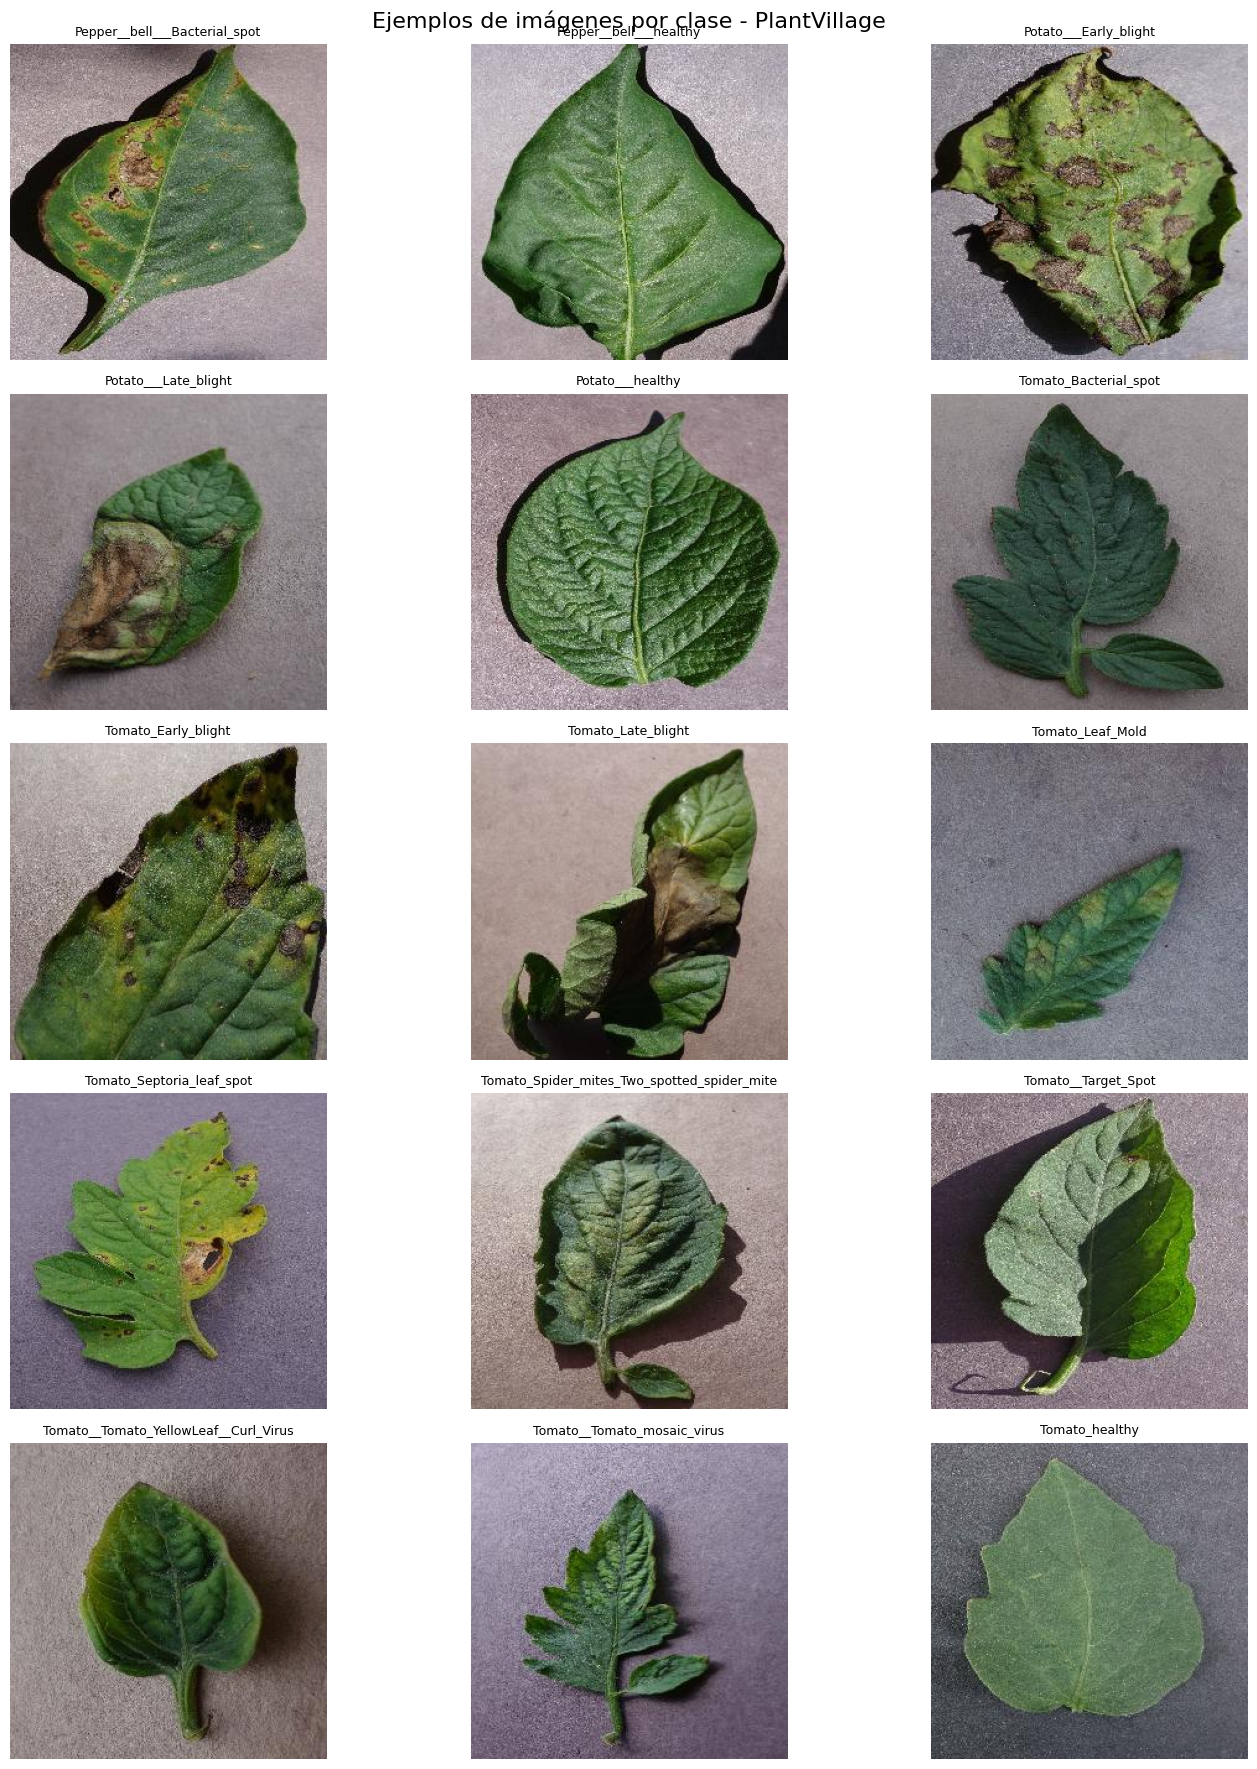

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

#clases disponibles
clases = sorted([
    clase for clase in os.listdir(ruta_dataset)
    if os.path.isdir(os.path.join(ruta_dataset, clase))
])

#figura para mostrar las imágenes
fig, axes = plt.subplots(5, 3, figsize=(15, 18))

for i, clase in enumerate(clases):

    ruta_clase = os.path.join(ruta_dataset, clase)
    imagenes = sorted([
        archivo for archivo in os.listdir(ruta_clase)
        if archivo.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    ruta_imagen = os.path.join(ruta_clase, imagenes[0])
    with Image.open(ruta_imagen) as img:
        imagen = img.convert("RGB")

    axes.flat[i].imshow(imagen)
    axes.flat[i].set_title(clase, fontsize=9)
    axes.flat[i].axis("off")

plt.suptitle(
    "Ejemplos de imágenes por clase - PlantVillage",
    fontsize=16
)

plt.tight_layout()
plt.show()

La visualización de las 15 clases permitió identificar diferencias en las características visuales de las hojas, principalmente relacionadas con su coloración, textura, forma y presencia de lesiones.
Las imágenes correspondientes a plantas saludables presentan una coloración predominantemente verde, mientras que algunas hojas clasificadas con enfermedades muestran manchas, decoloraciones y alteraciones en su estructura.
También se observaron similitudes visuales entre ciertas enfermedades, lo que podría representar un desafío para los modelos de clasificación.
Adicionalmente, las imágenes presentan fondos relativamente uniformes, característica que podría facilitar el aprendizaje, pero también limitar la capacidad de generalización ante imágenes capturadas en condiciones diferentes.
A partir de estas observaciones, se considera necesario aplicar técnicas de preprocesamiento que permitan estandarizar las imágenes antes de utilizarlas en el entrenamiento de las redes neuronales convolucionales.

## **4. Preprocesamiento y preparación de imágenes**
En esta etapa se prepararán las imágenes del conjunto de datos PlantVillage para su utilización en los modelos de redes neuronales convolucionales (CNN).
Siguiendo la metodología utilizada en la práctica de clases, se reducirá la cantidad de imágenes utilizadas y se estandarizarán sus dimensiones para disminuir el tiempo de procesamiento y entrenamiento.
A diferencia del dataset MNIST, las imágenes de PlantVillage contienen información de color relevante para identificar enfermedades, por lo que se mantendrán los tres canales RGB.
Se utilizarán imágenes de 64 × 64 píxeles, conservando una cantidad reducida de muestras para realizar un entrenamiento inicial eficiente.
Además, se aplicará una normalización de los valores de los píxeles al intervalo [0, 1], dividiendo sus valores originales entre 255.
Finalmente, los datos se dividirán de manera estratificada en conjuntos de entrenamiento, validación y prueba, manteniendo una semilla aleatoria fija para facilitar la reproducibilidad y la comparación posterior de modelos.

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

ruta_dataset = "/content/PlantVillage/PlantVillage"

#listado de imágenes y etiquetas
datos = []

for clase in sorted(os.listdir(ruta_dataset)):
    ruta_clase = os.path.join(ruta_dataset, clase)
    if os.path.isdir(ruta_clase):
        for archivo in sorted(os.listdir(ruta_clase)):
            if archivo.lower().endswith((".jpg", ".jpeg", ".png")):
                datos.append({
                    "ruta": os.path.join(ruta_clase, archivo),
                    "clase": clase
                })

df_imagenes = pd.DataFrame(datos)
df_muestra, _ = train_test_split(
    df_imagenes,
    train_size=4200,
    stratify=df_imagenes["clase"],
    random_state=42
)

df_train, df_temp = train_test_split(
    df_muestra,
    train_size=3000,
    stratify=df_muestra["clase"],
    random_state=42
)

df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    stratify=df_temp["clase"],
    random_state=42
)

print("Entrenamiento:", len(df_train))
print("Validación:", len(df_val))
print("Prueba:", len(df_test))

Entrenamiento: 3000
Validación: 600
Prueba: 600


## **4.1 Normalizacion de imagenes**

In [ ]:
import numpy as np
from PIL import Image

IMG_SIZE = 64
def preparar_imagenes(df):

    X = []
    y = []

    for _, fila in df.iterrows():
        with Image.open(fila["ruta"]) as img:
            img = img.convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))
            img_array = np.asarray(img, dtype=np.float32) / 255.0

        X.append(img_array)
        y.append(fila["clase"])

    return np.array(X), np.array(y)


X_train, y_train = preparar_imagenes(df_train)
X_val, y_val = preparar_imagenes(df_val)
X_test, y_test = preparar_imagenes(df_test)

print("Dimensiones X_train:", X_train.shape)
print("Dimensiones X_val:", X_val.shape)
print("Dimensiones X_test:", X_test.shape)

Dimensiones X_train: (3000, 64, 64, 3)
Dimensiones X_val: (600, 64, 64, 3)
Dimensiones X_test: (600, 64, 64, 3)


Para preparar las imágenes del dataset PlantVillage se tomaron tres decisiones principales:

**1. Redimensionamiento a 64 × 64 píxeles:**
Se seleccionó esta resolución para reducir el costo computacional y los tiempos de entrenamiento. Aunque una resolución mayor podría conservar detalles más pequeños de las enfermedades, 64 × 64 permite desarrollar una primera aproximación al problema utilizando recursos limitados.

**2. Conservación de los canales RGB:**
Se mantuvieron los tres canales de color porque las enfermedades vegetales pueden manifestarse mediante cambios de coloración, manchas y alteraciones en la superficie de las hojas. Convertir las imágenes a escala de grises podría eliminar información útil para su clasificación.

**3. Normalización entre 0 y 1:**
Los valores originales de los píxeles se dividieron entre 255 para trabajar con entradas en un rango numérico reducido. Esta transformación facilita el proceso de optimización y permite mantener una escala consistente entre las imágenes.

Estas decisiones buscan equilibrar la información visual disponible con los recursos computacionales necesarios para entrenar las redes convolucionales.

Para el desarrollo inicial del modelo, se decidió trabajar con una muestra de 4.200 imágenes del dataset PlantVillage, considerando la cantidad de clases disponibles y la necesidad de optimizar los recursos computacionales durante el entrenamiento.
Del total seleccionado, se destinarán 3.000 imágenes para entrenamiento, 600 para validación y 600 para prueba, permitiendo evaluar el aprendizaje del modelo en diferentes etapas.
La selección se realizará mediante un muestreo estratificado, con el propósito de mantener aproximadamente la proporción original de las 15 clases y asegurar que todas estén representadas.
Esta decisión permitirá realizar un entrenamiento inicial con tiempos de ejecución más reducidos, facilitando la identificación de posibles errores y la evaluación del comportamiento de la CNN.
Sin embargo, debido al desbalance identificado durante el análisis exploratorio, se reconoce que algunas clases tendrán una menor cantidad de ejemplos disponibles, lo que podría afectar su reconocimiento.
Por esta razón, se considerará la posibilidad de ampliar posteriormente la cantidad de imágenes utilizadas, dependiendo de los resultados obtenidos y del rendimiento del modelo.

## **4.2 Codificación de etiquetas**
Una vez preparadas las imágenes, se realizará la codificación de las etiquetas correspondientes a las 15 clases del conjunto de datos.
Debido a que las categorías se encuentran representadas mediante nombres de enfermedades y estados saludables, será necesario transformarlas en valores numéricos para facilitar su procesamiento durante el entrenamiento de la red neuronal.
Para ello, se utilizará una codificación que asigne un identificador único a cada clase, manteniendo la misma correspondencia en los conjuntos de entrenamiento, validación y prueba.
Este procedimiento permitirá relacionar correctamente las imágenes con sus respectivas categorías durante el aprendizaje y la evaluación del modelo.

In [ ]:
from sklearn.preprocessing import LabelEncoder

#codificador de etiquetas
label_encoder = LabelEncoder()
label_encoder.fit(df_imagenes["clase"])

#etiquetas a valores numericos
y_train = label_encoder.transform(y_train)
y_val = label_encoder.transform(y_val)
y_test = label_encoder.transform(y_test)


class_names = label_encoder.classes_

print("Codificación de clases:")

for i, clase in enumerate(class_names):
    print(f"{i}: {clase}")

print("\nCantidad de clases:", len(class_names))
print("Dimensiones y_train:", y_train.shape)
print("Dimensiones y_val:", y_val.shape)
print("Dimensiones y_test:", y_test.shape)

Codificación de clases:
0: Pepper__bell___Bacterial_spot
1: Pepper__bell___healthy
2: Potato___Early_blight
3: Potato___Late_blight
4: Potato___healthy
5: Tomato_Bacterial_spot
6: Tomato_Early_blight
7: Tomato_Late_blight
8: Tomato_Leaf_Mold
9: Tomato_Septoria_leaf_spot
10: Tomato_Spider_mites_Two_spotted_spider_mite
11: Tomato__Target_Spot
12: Tomato__Tomato_YellowLeaf__Curl_Virus
13: Tomato__Tomato_mosaic_virus
14: Tomato_healthy

Cantidad de clases: 15
Dimensiones y_train: (3000,)
Dimensiones y_val: (600,)
Dimensiones y_test: (600,)


Una vez finalizada la preparación de los datos, se verificará que los conjuntos de entrenamiento, validación y prueba presenten las dimensiones esperadas.
También se comprobará que los valores de los píxeles se encuentren normalizados en el intervalo [0, 1] y que las etiquetas numéricas correspondan a las 15 clases identificadas.
Esta revisión permitirá confirmar que los datos se encuentran preparados para ser utilizados en el entrenamiento de las redes neuronales convolucionales.

In [ ]:
import numpy as np

#dimensiones de imag. y etiquetas
for nombre, X, y in [
    ("Entrenamiento", X_train, y_train),
    ("Validación", X_val, y_val),
    ("Prueba", X_test, y_test)
]:
    print(f"\n{nombre}")
    print("Imágenes:", X.shape)
    print("Etiquetas:", y.shape)
    print("Píxel mínimo:", X.min())
    print("Píxel máximo:", X.max())
    print("Clases presentes:", len(np.unique(y)))

    #consistencia de los datos
    assert len(X) == len(y), "Cantidad de imágenes y etiquetas diferente"
    assert X.shape[1:] == (64, 64, 3), "Dimensiones incorrectas"
    assert X.min() >= 0 and X.max() <= 1, "Normalización incorrecta"
    assert np.all((y >= 0) & (y < 15)), "Etiquetas fuera de rango"

print("\nVerificación del preprocesamiento completada.")


Entrenamiento
Imágenes: (3000, 64, 64, 3)
Etiquetas: (3000,)
Píxel mínimo: 0.0
Píxel máximo: 1.0
Clases presentes: 15

Validación
Imágenes: (600, 64, 64, 3)
Etiquetas: (600,)
Píxel mínimo: 0.0
Píxel máximo: 1.0
Clases presentes: 15

Prueba
Imágenes: (600, 64, 64, 3)
Etiquetas: (600,)
Píxel mínimo: 0.0
Píxel máximo: 0.9882353
Clases presentes: 15

Verificación del preprocesamiento completada.


La etapa de preprocesamiento se completó correctamente, obteniendo tres conjuntos de datos: 3.000 imágenes para entrenamiento, 600 para validación y 600 para prueba.
Todas las imágenes fueron redimensionadas a 64 × 64 píxeles, conservando sus tres canales RGB. Asimismo, se normalizaron los valores de los píxeles al intervalo [0, 1].
La verificación permitió confirmar que los tres conjuntos mantienen las 15 clases originales y que existe correspondencia entre la cantidad de imágenes y sus respectivas etiquetas.
Estos resultados indican que los datos cumplen con las condiciones definidas para iniciar el entrenamiento de los modelos CNN.
Sin embargo, debido a la reducción del conjunto de datos y al desbalance identificado anteriormente, será necesario analizar el desempeño de los modelos en las distintas clases durante la evaluación.

## **5. Construcción y entrenamiento de la CNN base**
### **5.1. Definición de la arquitectura**
Se implementará una red neuronal convolucional (CNN) para clasificar las imágenes de hojas de plantas en las 15 categorías identificadas.
La arquitectura estará compuesta por capas convolucionales encargadas de extraer características visuales, capas de agrupamiento (MaxPooling) para reducir las dimensiones de los mapas de características y capas densas para realizar la clasificación.
Se utilizará la función de activación ReLU en las capas intermedias y Softmax en la capa de salida, permitiendo obtener una distribución de probabilidades entre las 15 clases.
Se seleccionará una arquitectura relativamente sencilla con el objetivo de mantener tiempos de entrenamiento razonables y establecer un modelo base que posteriormente pueda compararse con otras configuraciones.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

#semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

#onstruir arquitectura CNN base
modelo_base = models.Sequential([

    layers.Input(shape=(64, 64, 3)),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(
        15,
        activation="softmax"
    )

])

modelo_base.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 823,247 (3.14 MB)

 Trainable params: 823,247 (3.14 MB)

 Non-trainable params: 0 (0.00 B)

La arquitectura inicial se diseñó como un modelo de referencia que permita evaluar la capacidad de una CNN sencilla para identificar enfermedades en imágenes de hojas.

**Primera capa convolucional (32 filtros, 3 × 3):**
Permite identificar características visuales iniciales, como bordes, variaciones de color y patrones locales presentes en las hojas.

**Segunda capa convolucional (64 filtros, 3 × 3):**
Incrementa la cantidad de filtros para aprender representaciones visuales más complejas a partir de las características extraídas anteriormente.

**Capas MaxPooling (2 × 2):**
Reducen las dimensiones espaciales de los mapas de características, disminuyendo el costo computacional y conservando las activaciones más relevantes de cada región.

**Capa Flatten:**
Transforma los mapas de características en un vector que puede ser procesado por las capas densas.

**Capa Dense de 64 neuronas:**
Combina las características aprendidas por las capas convolucionales para facilitar la clasificación.

**Función de activación ReLU:**
Introduce no linealidad en la red y permite aprender relaciones complejas entre las características visuales.

**Capa de salida Softmax (15 neuronas):**
Entrega una distribución de probabilidades entre las 15 clases del dataset. Se seleccionó Softmax porque cada imagen pertenece a una única categoría.

La arquitectura se mantuvo relativamente sencilla para establecer una referencia inicial de rendimiento. Su desempeño permitirá determinar posteriormente si resulta conveniente utilizar una estructura más profunda y técnicas adicionales de regularización.

Una vez definida la arquitectura CNN, se procederá a configurar los elementos necesarios para su entrenamiento.
Se utilizará el optimizador Adam, debido a su capacidad para ajustar automáticamente la tasa de aprendizaje de los parámetros durante el entrenamiento.
Como función de pérdida se seleccionará Sparse Categorical Crossentropy, adecuada para problemas de clasificación multiclase en los que las etiquetas están representadas mediante valores enteros.
Finalmente, se utilizará la métrica Accuracy para monitorear la proporción de predicciones correctas realizadas por el modelo.
Esta configuración permitirá establecer un modelo base y analizar su comportamiento durante el proceso de aprendizaje.

In [ ]:
#compilacion del modelo CNN base
modelo_base.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo CNN compilado correctamente.")

Modelo CNN compilado correctamente.


Para el entrenamiento inicial se utilizarán 3.000 imágenes, mientras que las 600 imágenes del conjunto de validación permitirán monitorear el comportamiento del modelo durante el aprendizaje.
Se establecerá un máximo de 10 épocas y un tamaño de lote (batch size) de 32 imágenes, buscando mantener tiempos de ejecución razonables.
Además, se implementará la técnica Early Stopping, que permitirá detener anticipadamente el entrenamiento si la pérdida de validación deja de mejorar durante tres épocas consecutivas.
Esta estrategia busca reducir el entrenamiento innecesario y restaurar los pesos correspondientes al mejor resultado de validación.
Durante el proceso se registrarán los valores de pérdida y precisión para analizar posteriormente la evolución del aprendizaje y detectar posibles señales de sobreajuste.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

#configuracion de la detención anticipada
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

#entrenando la CNN base
historial_base = modelo_base.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Entrenamiento finalizado correctamente.")

Epoch 1/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 18s 178ms/step - accuracy: 0.3133 - loss: 2.1171 - val_accuracy: 0.5183 - val_loss: 1.6577
Epoch 2/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 21s 188ms/step - accuracy: 0.5557 - loss: 1.4108 - val_accuracy: 0.5917 - val_loss: 1.3855
Epoch 3/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 17s 176ms/step - accuracy: 0.6503 - loss: 1.0896 - val_accuracy: 0.6767 - val_loss: 1.1318
Epoch 4/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 18s 194ms/step - accuracy: 0.7247 - loss: 0.8719 - val_accuracy: 0.7050 - val_loss: 1.0199
Epoch 5/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 19s 178ms/step - accuracy: 0.7770 - loss: 0.7162 - val_accuracy: 0.7200 - val_loss: 0.9210
Epoch 6/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 17s 179ms/step - accuracy: 0.8220 - loss: 0.5717 - val_accuracy: 0.7117 - val_loss: 0.9559
Epoch 7/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 17s 180ms/step - accuracy: 0.8520 - loss: 0.4741 - val_accuracy: 0.6950 - val_loss: 0.9641
Epoch 8/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 18s 187ms/step - accuracy: 0.8853 - loss: 0.3645 - val_accu

## **5.2 Visualización de las curvas de aprendizaje**
Para analizar el comportamiento de la CNN durante el entrenamiento, se visualizará la evolución de las métricas de precisión (accuracy) y pérdida (loss) a lo largo de las épocas ejecutadas.
Se compararán los resultados obtenidos en los conjuntos de entrenamiento y validación, con el propósito de identificar si el modelo presenta mejoras progresivas en su aprendizaje.
Además, estas visualizaciones permitirán detectar posibles señales de sobreajuste, observando las diferencias entre el rendimiento sobre los datos de entrenamiento y aquellos utilizados para validación.

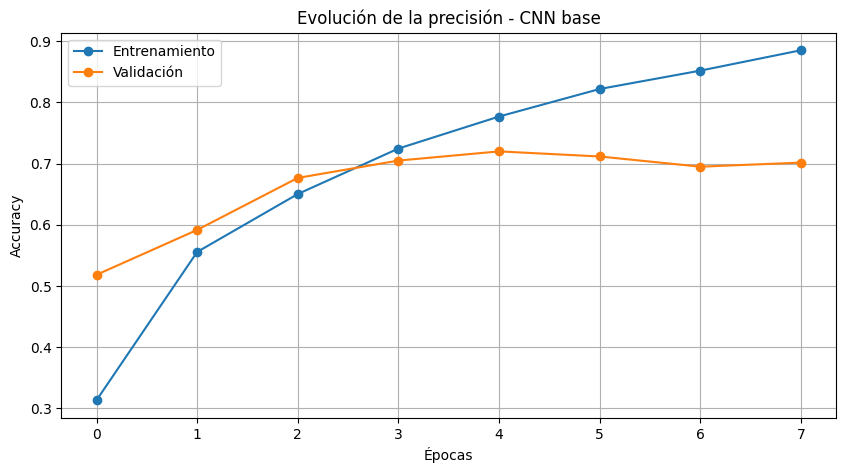

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

#precision del entrenamiento
plt.plot(
    historial_base.history["accuracy"],
    label="Entrenamiento",
    marker="o"
)

#precision de la validación
plt.plot(
    historial_base.history["val_accuracy"],
    label="Validación",
    marker="o"
)

plt.title("Evolución de la precisión - CNN base")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

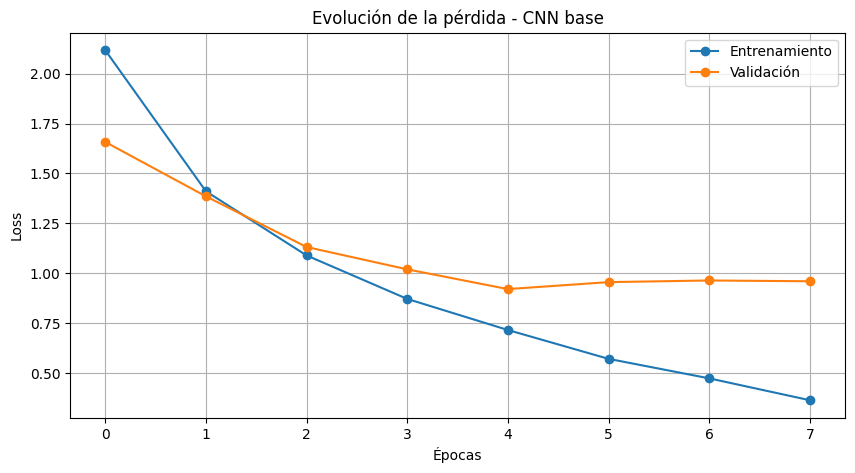

In [ ]:
#grafico de pérdida
plt.figure(figsize=(10, 5))
plt.plot(
    historial_base.history["loss"],
    label="Entrenamiento",
    marker="o"
)

#perdida de la validacion
plt.plot(
    historial_base.history["val_loss"],
    label="Validación",
    marker="o"
)

plt.title("Evolución de la pérdida - CNN base")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

A partir de los gráficos obtenidos, se observa que la CNN logró mejorar progresivamente su precisión durante el entrenamiento, pasando de un 31,33 % en la primera época a un 88,53 % en la última.
Sin embargo, al analizar los resultados de validación, se identifica que el mejor desempeño se alcanzó en la quinta época, con una precisión del 72 % y una pérdida de 0,9210.
Después de esta etapa, la precisión de entrenamiento continuó aumentando, mientras que la precisión de validación se mantuvo cercana al 70 %, sin presentar mejoras significativas.
Este comportamiento también se refleja en el gráfico de pérdida, donde se observa que el error de entrenamiento continúa disminuyendo, pero el de validación comienza a aumentar ligeramente.
Estos resultados sugieren que el modelo presenta señales de sobreajuste, debido a que logra reconocer mejor las imágenes utilizadas durante el entrenamiento que aquellas destinadas a validación.
La implementación de Early Stopping permitió detener el entrenamiento en la octava época y recuperar los pesos de la quinta, evitando continuar con un proceso que no estaba generando mejoras en la validación.
En general, los resultados muestran que la CNN logró aprender características relevantes de las imágenes, aunque todavía presenta oportunidades de mejora en su capacidad de generalización. Por esta razón, se utilizará como modelo base para comparar posteriormente su desempeño con una segunda arquitectura.

## 5.2.1 Experimentación y comparación de hiperparámetros

Con el objetivo de analizar cómo influyen los hiperparámetros en el rendimiento de la CNN base, se realizarán experimentos modificando la tasa de aprendizaje (learning rate) y el tamaño de lote (batch size).

Se evaluarán las siguientes configuraciones:

| Experimento | Learning rate | Batch size |
|---|---|---|
| 1 | 0.001 | 32 |
| 2 | 0.0001 | 32 |
| 3 | 0.001 | 64 |
| 4 | 0.0001 | 64 |

Para mantener condiciones de comparación equivalentes, se utilizará la misma arquitectura CNN, la misma división de datos, una semilla fija y el mismo máximo de épocas.

Se utilizarán las métricas accuracy y F1-score macro sobre el conjunto de validación para comparar los resultados.

Esta experimentación permitirá identificar qué configuración presenta un mejor desempeño en los datos de validación, sin utilizar el conjunto de prueba durante la selección de hiperparámetros.

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np

from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score

#configuraciones a evaluar
configuraciones = [
    (0.001, 32),
    (0.0001, 32),
    (0.001, 64),
    (0.0001, 64)
]

resultados_experimentos = []

#evaluacion de todas las configuracin
for i, (lr, batch) in enumerate(configuraciones, start=1):

    print(f"\nExperimento {i}")
    print(f"Learning rate: {lr}")
    print(f"Batch size: {batch}")

    #reiniciar sesión y fijar semilla
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Crear una CNN nueva con la misma arquitectura base
    modelo_exp = tf.keras.models.clone_model(modelo_base)

    #compilar con el learning rate correspondiente
    modelo_exp.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    #configuecion de Early Stopping
    early_exp = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    #enntrenar el modelo
    historial_exp = modelo_exp.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=batch,
        callbacks=[early_exp],
        verbose=0
    )

    #predicciones sobre validacion
    probabilidades = modelo_exp.predict(
        X_val,
        verbose=0
    )

    y_pred = np.argmax(probabilidades, axis=1)

    #calculo demetricas de validacion
    accuracy = accuracy_score(y_val, y_pred)

    f1 = f1_score(
        y_val,
        y_pred,
        average="macro",
        zero_division=0
    )

    resultados_experimentos.append({
        "Experimento": i,
        "Learning Rate": lr,
        "Batch Size": batch,
        "Épocas ejecutadas": len(historial_exp.history["loss"]),
        "Accuracy Validación": accuracy,
        "F1 Macro Validación": f1
    })

#tabla comparativa
df_experimentos = pd.DataFrame(
    resultados_experimentos
)

display(df_experimentos)


Experimento 1
Learning rate: 0.001
Batch size: 32

Experimento 2
Learning rate: 0.0001
Batch size: 32

Experimento 3
Learning rate: 0.001
Batch size: 64

Experimento 4
Learning rate: 0.0001
Batch size: 64


,Experimento,Learning Rate,Batch Size,Épocas ejecutadas,Accuracy Validación,F1 Macro Validación
0,1,0.0010,32,7,0.725000,0.641699
1,2,0.0001,32,10,0.641667,0.543498
2,3,0.0010,64,10,0.740000,0.654519
3,4,0.0001,64,10,0.606667,0.490591


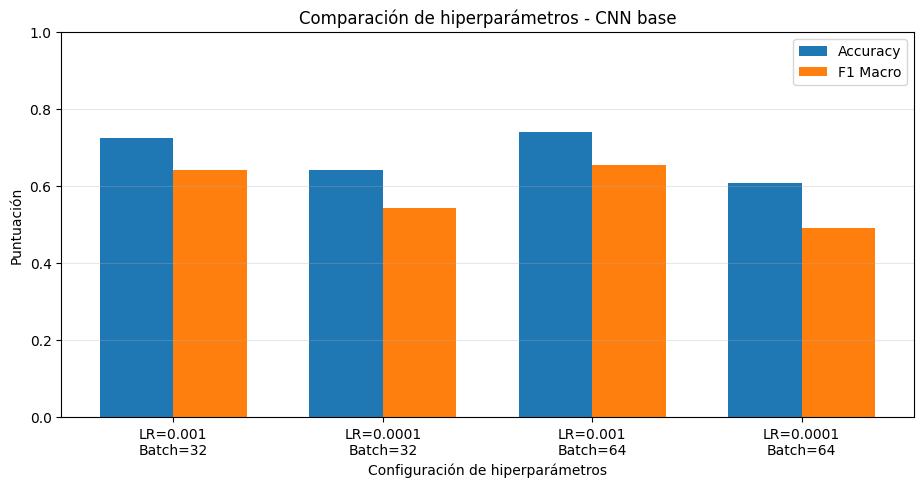

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

etiquetas = [
    f"LR={lr}\nBatch={batch}"
    for lr, batch in configuraciones
]

x = np.arange(len(etiquetas))
ancho = 0.35

plt.figure(figsize=(11, 5))

#accuracy
plt.bar(
    x - ancho / 2,
    df_experimentos["Accuracy Validación"],
    width=ancho,
    label="Accuracy"
)

#F1-score macro
plt.bar(
    x + ancho / 2,
    df_experimentos["F1 Macro Validación"],
    width=ancho,
    label="F1 Macro"
)

plt.xlabel("Configuración de hiperparámetros")
plt.ylabel("Puntuación")
plt.title("Comparación de hiperparámetros - CNN base")
plt.xticks(x, etiquetas)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
#configuracion con mejor F1 macro
mejor_experimento = df_experimentos.loc[
    df_experimentos["F1 Macro Validación"].idxmax()
]

print("Mejor configuración según F1 macro:")
print("Learning rate:", mejor_experimento["Learning Rate"])
print("Batch size:", int(mejor_experimento["Batch Size"]))
print("Accuracy:", round(mejor_experimento["Accuracy Validación"], 4))
print("F1 Macro:", round(mejor_experimento["F1 Macro Validación"], 4))

Mejor configuración según F1 macro:
Learning rate: 0.001
Batch size: 64
Accuracy: 0.74
F1 Macro: 0.6545


Se realizaron cuatro experimentos modificando la tasa de aprendizaje (learning rate) y el tamaño de lote (batch size) de la CNN base, manteniendo la misma arquitectura y división de datos.  
**Análisis de la tasa de aprendizaje**  
Los resultados muestran que la tasa de aprendizaje de 0.001 obtuvo un mejor rendimiento que 0.0001 en ambos tamaños de lote evaluados.
Con un batch size de 32, el F1-score macro disminuyó de 0.6417 a 0.5435 al reducir el learning rate. De manera similar, con un batch size de 64, disminuyó de 0.6545 a 0.4906.
Estos resultados sugieren que una tasa de aprendizaje demasiado pequeña puede limitar la velocidad de convergencia cuando se dispone de un número reducido de épocas.  
**Análisis del tamaño de lote**  
Con un learning rate de 0.001, aumentar el batch size de 32 a 64 permitió mejorar la accuracy de validación de 72.50 % a 74.00 %, mientras que el F1-score macro aumentó de 0.6417 a 0.6545.
Sin embargo, con un learning rate de 0.0001, aumentar el batch size produjo una disminución del rendimiento. Esto evidencia que el efecto del tamaño de lote depende de la tasa de aprendizaje utilizada.  
**Identificación de la mejor configuración**  
El experimento 3, utilizando Adam con learning rate de 0.001 y batch size de 64, obtuvo los mejores resultados entre las configuraciones evaluadas:
*  Accuracy de validación: 74.00 %.
*  F1-score macro de validación: 0.6545.
*  Épocas ejecutadas: 10.  

Esta configuración presentó el mejor equilibrio de rendimiento entre las alternativas evaluadas, tomando el F1-score macro como criterio principal.  
**Limitaciones del experimento**  
Los experimentos se realizaron con una única semilla y un máximo de 10 épocas. Por lo tanto, las diferencias pequeñas entre configuraciones podrían variar al repetir el entrenamiento.
Además, las configuraciones con learning rate de 0.0001 podrían necesitar más épocas para alcanzar un rendimiento comparable.
Por esta razón, los resultados permiten seleccionar la configuración más favorable dentro de las condiciones evaluadas, pero no establecer que sea óptima para cualquier escenario.
Esta comparación nos permitió comprobar que la selección de hiperparámetros influye en el desempeño de la CNN y que su efecto debe analizarse considerando las combinaciones utilizadas.
La configuración con learning rate de 0.001 y batch size de 64 obtuvo el mejor rendimiento de validación en los experimentos realizados, proporcionando evidencia para justificar técnicamente esta selección.

## **5.3 Guardado del modelo CNN base**
Una vez finalizado el entrenamiento y analizados los resultados obtenidos, se guardará el modelo CNN base para conservar su arquitectura y los parámetros aprendidos.
Esto permitirá utilizarlo posteriormente sin necesidad de repetir el entrenamiento, facilitando su evaluación y comparación con una segunda arquitectura.
El modelo se almacenará en Google Drive, de manera que pueda recuperarse en futuras sesiones de Google Colab.
Esta etapa permitirá mantener los resultados del primer entrenamiento y dar continuidad al desarrollo del proyecto.

In [ ]:
import os

#carpeta de almacenamiento
ruta_modelos = "/content/drive/MyDrive/Prueba2_DeepLearning"
os.makedirs(ruta_modelos, exist_ok=True)

#CNN base guardado en la carpeta
ruta_modelo_base = os.path.join(
    ruta_modelos,
    "modelo_cnn_base.keras"
)
modelo_base.save(ruta_modelo_base)

print("Modelo CNN base guardado correctamente.")
print("Ubicación:", ruta_modelo_base)

Modelo CNN base guardado correctamente.
Ubicación: /content/drive/MyDrive/Prueba2_DeepLearning/modelo_cnn_base.keras


## **5.4 Guardado de la división del dataset**
Para garantizar la reproducibilidad del proyecto, se almacenará la distribución de las imágenes utilizadas durante el entrenamiento, validación y prueba.
Se generará un archivo CSV que contendrá el nombre de cada imagen, su clase correspondiente y el conjunto al que fue asignada.
Esto permitirá utilizar la misma selección de datos en el entrenamiento de una segunda arquitectura CNN, asegurando condiciones equivalentes para la comparación de ambos modelos.
Además, se evitará depender exclusivamente de la selección aleatoria realizada durante la ejecución inicial.

In [ ]:
import pandas as pd

train_export = df_train.copy()
val_export = df_val.copy()
test_export = df_test.copy()
train_export["conjunto"] = "entrenamiento"
val_export["conjunto"] = "validacion"
test_export["conjunto"] = "prueba"

division_datos = pd.concat(
    [train_export, val_export, test_export],
    ignore_index=True
)
division_datos["ruta"] = division_datos["ruta"].apply(
    lambda ruta: os.path.relpath(ruta, ruta_dataset)
)

ruta_division = os.path.join(
    ruta_modelos,
    "division_datos.csv"
)

division_datos.to_csv(
    ruta_division,
    index=False,
    encoding="utf-8-sig"
)

print("División del dataset guardada correctamente.")
print(division_datos["conjunto"].value_counts())

División del dataset guardada correctamente.
conjunto
entrenamiento    3000
validacion        600
prueba            600
Name: count, dtype: int64


## **5.5 Guardado de la codificación de clases**
Para mantener la consistencia en la clasificación, se almacenará la correspondencia entre las 15 categorías del conjunto de datos y sus respectivos identificadores numéricos.
Esta información permitirá recuperar las etiquetas originales y asegurar que ambas arquitecturas utilicen la misma codificación durante el entrenamiento y la evaluación.
De esta manera, se facilitará la interpretación de las predicciones y la comparación posterior de los resultados.

In [ ]:
import json

#diccionario de clases
diccionario_clases = {
    int(i): str(clase)
    for i, clase in enumerate(class_names)
}

#guardado de codificación
ruta_clases = os.path.join(
    ruta_modelos,
    "clases.json"
)

with open(ruta_clases, "w", encoding="utf-8") as archivo:
    json.dump(
        diccionario_clases,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Codificación de clases guardada correctamente.")
print("Total de clases:", len(diccionario_clases))

Codificación de clases guardada correctamente.
Total de clases: 15


## 6. Segunda arquitectura CNN


### **6.1 Preparación de los datos**

Para el desarrollo de la segunda arquitectura CNN, se utilizará la misma muestra de 4.200 imágenes seleccionada durante el preprocesamiento inicial.

Se recuperará la división del dataset y la codificación de las 15 clases previamente guardadas, manteniendo 3.000 imágenes para entrenamiento, 600 para validación y 600 para prueba.

Las imágenes se redimensionarán a 64 × 64 píxeles y se normalizarán entre 0 y 1, conservando las mismas condiciones utilizadas en la CNN base para permitir una comparación de resultados.


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import json
import zipfile
import numpy as np
import pandas as pd
from PIL import Image

#rutas de los archivos
ruta_drive = "/content/drive/MyDrive/Prueba2_DeepLearning"
ruta_zip = os.path.join(ruta_drive, "PlantVillage.zip")
ruta_destino = "/content/PlantVillage"
ruta_dataset = os.path.join(ruta_destino, "PlantVillage")

#carga de la división del dataset
division_datos = pd.read_csv(
    os.path.join(ruta_drive, "division_datos.csv")
)

#carga de la codificación de clases
with open(os.path.join(ruta_drive, "clases.json"),
          "r", encoding="utf-8") as archivo:
    diccionario_clases = json.load(archivo)

class_names = [
    diccionario_clases[str(i)]
    for i in range(len(diccionario_clases))
]

#extracción de las imágenes seleccionadas
os.makedirs(ruta_destino, exist_ok=True)

with zipfile.ZipFile(ruta_zip, "r") as zip_ref:
    archivos_zip = set(zip_ref.namelist())

    for ruta in division_datos["ruta"].unique():
        ruta_relativa = ruta.replace("\\", "/")
        archivo_zip = "PlantVillage/" + ruta_relativa

        if archivo_zip not in archivos_zip:
            raise FileNotFoundError(archivo_zip)

        if not os.path.isfile(
            os.path.join(ruta_dataset, ruta_relativa)
        ):
            zip_ref.extract(archivo_zip, ruta_destino)

#separación de los conjuntos
df_train = division_datos[
    division_datos["conjunto"] == "entrenamiento"
]
df_val = division_datos[
    division_datos["conjunto"] == "validacion"
]
df_test = division_datos[
    division_datos["conjunto"] == "prueba"
]

#preparación y normalización de imágenes
IMG_SIZE = 64

def preparar_imagenes(df):
    X = []
    y = []

    for _, fila in df.iterrows():
        ruta_imagen = os.path.join(
            ruta_dataset, fila["ruta"]
        )

        with Image.open(ruta_imagen) as img:
            img = img.convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))
            img_array = np.asarray(
                img, dtype=np.float32
            ) / 255.0

        X.append(img_array)
        y.append(class_names.index(fila["clase"]))

    return np.array(X), np.array(y)

X_train, y_train = preparar_imagenes(df_train)
X_val, y_val = preparar_imagenes(df_val)
X_test, y_test = preparar_imagenes(df_test)

print("Dimensiones X_train:", X_train.shape)
print("Dimensiones X_val:", X_val.shape)
print("Dimensiones X_test:", X_test.shape)
print("Cantidad de clases:", len(class_names))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensiones X_train: (3000, 64, 64, 3)
Dimensiones X_val: (600, 64, 64, 3)
Dimensiones X_test: (600, 64, 64, 3)
Cantidad de clases: 15


### **6.2 Definición de la segunda arquitectura CNN**

Se construye una segunda red neuronal convolucional (CNN) con modificaciones respecto al modelo base, buscando reducir el sobreajuste y mejorar su capacidad de generalización.

La nueva arquitectura incorpora tres bloques convolucionales con 32, 64 y 128 filtros, junto con capas Batch Normalization y Dropout. Además, se reemplaza Flatten por Global Average Pooling para reducir la cantidad de parámetros entrenables.

Se incorpora regularización L2 en la capa densa y se mantiene una capa de salida Softmax con 15 neuronas, correspondientes a las clases del dataset.

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

#semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

#definición de la segunda arquitectura CNN
modelo_cnn_2 = models.Sequential([

    layers.Input(shape=(64, 64, 3)),

    #primer bloque convolucional
    layers.Conv2D(32, (3, 3), activation="relu",
                  padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    #segundo bloque convolucional
    layers.Conv2D(64, (3, 3), activation="relu",
                  padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    #tercer bloque convolucional
    layers.Conv2D(128, (3, 3), activation="relu",
                  padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    #reducción de parámetros
    layers.GlobalAveragePooling2D(),

    #capa densa con regularización L2
    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.40),

    #capa de salida
    layers.Dense(15, activation="softmax")
])

#resumen de la arquitectura
modelo_cnn_2.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,375 (403.81 KB)

 Trainable params: 102,927 (402.06 KB)

 Non-trainable params: 448 (1.75 KB)

### **6.3 Compilación y entrenamiento del modelo**

Se compila la segunda CNN utilizando el optimizador Adam, la función de pérdida Sparse Categorical Crossentropy y accuracy como métrica de evaluación.

El entrenamiento se configura con un máximo de 20 épocas y un tamaño de lote de 32 imágenes. Se incorpora Early Stopping para detener el entrenamiento cuando la pérdida de validación deje de mejorar, restaurando los mejores pesos obtenidos.

Se utilizan los mismos conjuntos de entrenamiento y validación definidos anteriormente.

In [ ]:

#compilación del modelo
modelo_cnn_2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#detención temprana para reducir sobreajuste
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

#entrenamiento de la segunda CNN
historial_cnn_2 = modelo_cnn_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

#guardar el modelo entrenado en tu sesión de Colab
modelo_cnn_2.save("/content/modelo_cnn_2.keras")

print("Entrenamiento finalizado.")

Epoch 1/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 31s 179ms/step - accuracy: 0.4007 - loss: 1.9821 - val_accuracy: 0.0783 - val_loss: 3.0494
Epoch 2/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5613 - loss: 1.4458 - val_accuracy: 0.0783 - val_loss: 5.5359
Epoch 3/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6383 - loss: 1.2134 - val_accuracy: 0.0783 - val_loss: 7.0029
Epoch 4/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6857 - loss: 1.0776 - val_accuracy: 0.0783 - val_loss: 8.8373
Epoch 5/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7023 - loss: 0.9746 - val_accuracy: 0.2650 - val_loss: 4.1147
Epoch 6/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7500 - loss: 0.8660 - val_accuracy: 0.5233 - val_loss: 1.5686
Epoch 7/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7650 - loss: 0.7999 - val_accuracy: 0.4400 - val_loss: 1.8024
Epoch 8/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7943 - loss: 0.7322 - val_accuracy: 0.6600 - val

In [ ]:
modelo_cnn_2.save(
    "/content/drive/MyDrive/Colab Notebooks/modelo_cnn_2.keras"
)

### **6.4 Análisis de los resultados**



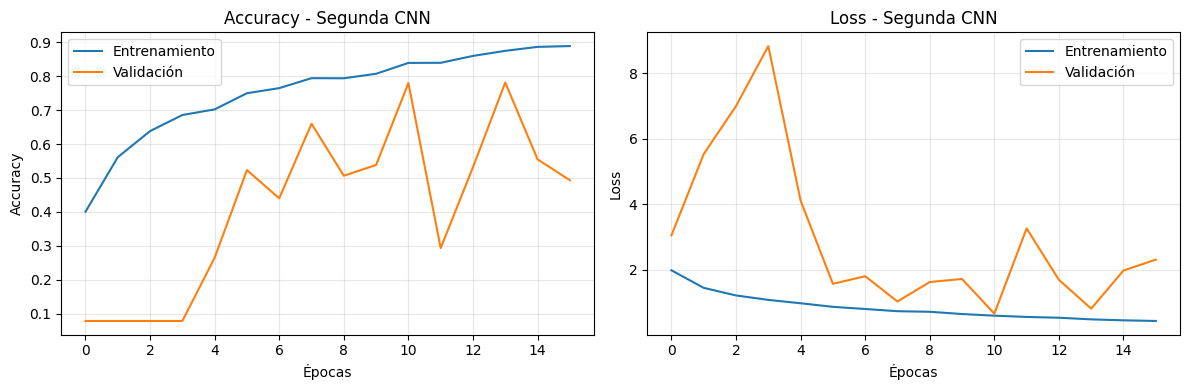

In [ ]:

import matplotlib.pyplot as plt

#gráficos de accuracy y loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#accuracy
axes[0].plot(
    historial_cnn_2.history["accuracy"],
    label="Entrenamiento"
)
axes[0].plot(
    historial_cnn_2.history["val_accuracy"],
    label="Validación"
)
axes[0].set_title("Accuracy - Segunda CNN")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

#loss
axes[1].plot(
    historial_cnn_2.history["loss"],
    label="Entrenamiento"
)
axes[1].plot(
    historial_cnn_2.history["val_loss"],
    label="Validación"
)
axes[1].set_title("Loss - Segunda CNN")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


La segunda CNN completó 16 épocas de entrenamiento, alcanzando un accuracy de 88,90 % en entrenamiento y un máximo de 78,17 % en validación.

Se observa una mejora progresiva del rendimiento sobre los datos de entrenamiento. Sin embargo, la validación presenta fluctuaciones importantes, lo que indica dificultades para mantener un rendimiento estable sobre imágenes no utilizadas durante el aprendizaje.

La menor pérdida de validación se obtuvo en la época 11, con un valor de 0,6579. Mediante Early Stopping se recuperaron los pesos correspondientes a esta época para conservar el modelo con mejor pérdida de validación.

Si bien se incorporaron técnicas de regularización para reducir el sobreajuste, los resultados muestran que persisten diferencias entre el comportamiento del entrenamiento y la validación.

Para determinar si estas modificaciones representan una mejora respecto a la CNN base, será necesario evaluar ambas arquitecturas utilizando el mismo conjunto de prueba.

## **7. Evaluación y comparación de modelos**


### **7.1 Evaluación de ambas arquitecturas CNN**

Para comparar el rendimiento de las dos arquitecturas, se utilizará el mismo conjunto de prueba compuesto por 600 imágenes.

Se evaluará la CNN base desarrollada inicialmente y la segunda CNN con técnicas de regularización, calculando accuracy, precision, recall y F1-score.

Estas métricas permitirán analizar la capacidad de clasificación de ambos modelos sobre imágenes no utilizadas durante el entrenamiento.

In [ ]:

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np
import os

#carga del modelo base de María
ruta_modelo_base = os.path.join(
    ruta_drive, "modelo_cnn_base.keras"
)

modelo_cnn_base = load_model(ruta_modelo_base)

#evaluación de ambas CNN con el mismo conjunto de prueba
pred_base = modelo_cnn_base.predict(X_test, verbose=0)
pred_cnn_2 = modelo_cnn_2.predict(X_test, verbose=0)

y_pred_base = np.argmax(pred_base, axis=1)
y_pred_cnn_2 = np.argmax(pred_cnn_2, axis=1)

#cálculo de métricas
def calcular_metricas(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(
            y_real, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_pred, average="macro", zero_division=0
        )
    }

resultados = pd.DataFrame({
    "CNN Base": calcular_metricas(y_test, y_pred_base),
    "CNN Mejorada": calcular_metricas(y_test, y_pred_cnn_2)
}).T

print("Comparación de métricas en el conjunto de prueba:")
display(resultados.round(4))


Comparación de métricas en el conjunto de prueba:


,Accuracy,Precision,Recall,F1-score
CNN Base,0.6950,0.6342,0.6171,0.6052
CNN Mejorada,0.7967,0.8396,0.7295,0.7524


### **7.2 Matrices de confusión**

Se generan las matrices de confusión de ambas arquitecturas utilizando las 600 imágenes del conjunto de prueba.

Estas matrices permiten identificar las clases que se clasifican correctamente y aquellas que presentan mayores dificultades, facilitando el análisis de los errores cometidos por cada modelo.

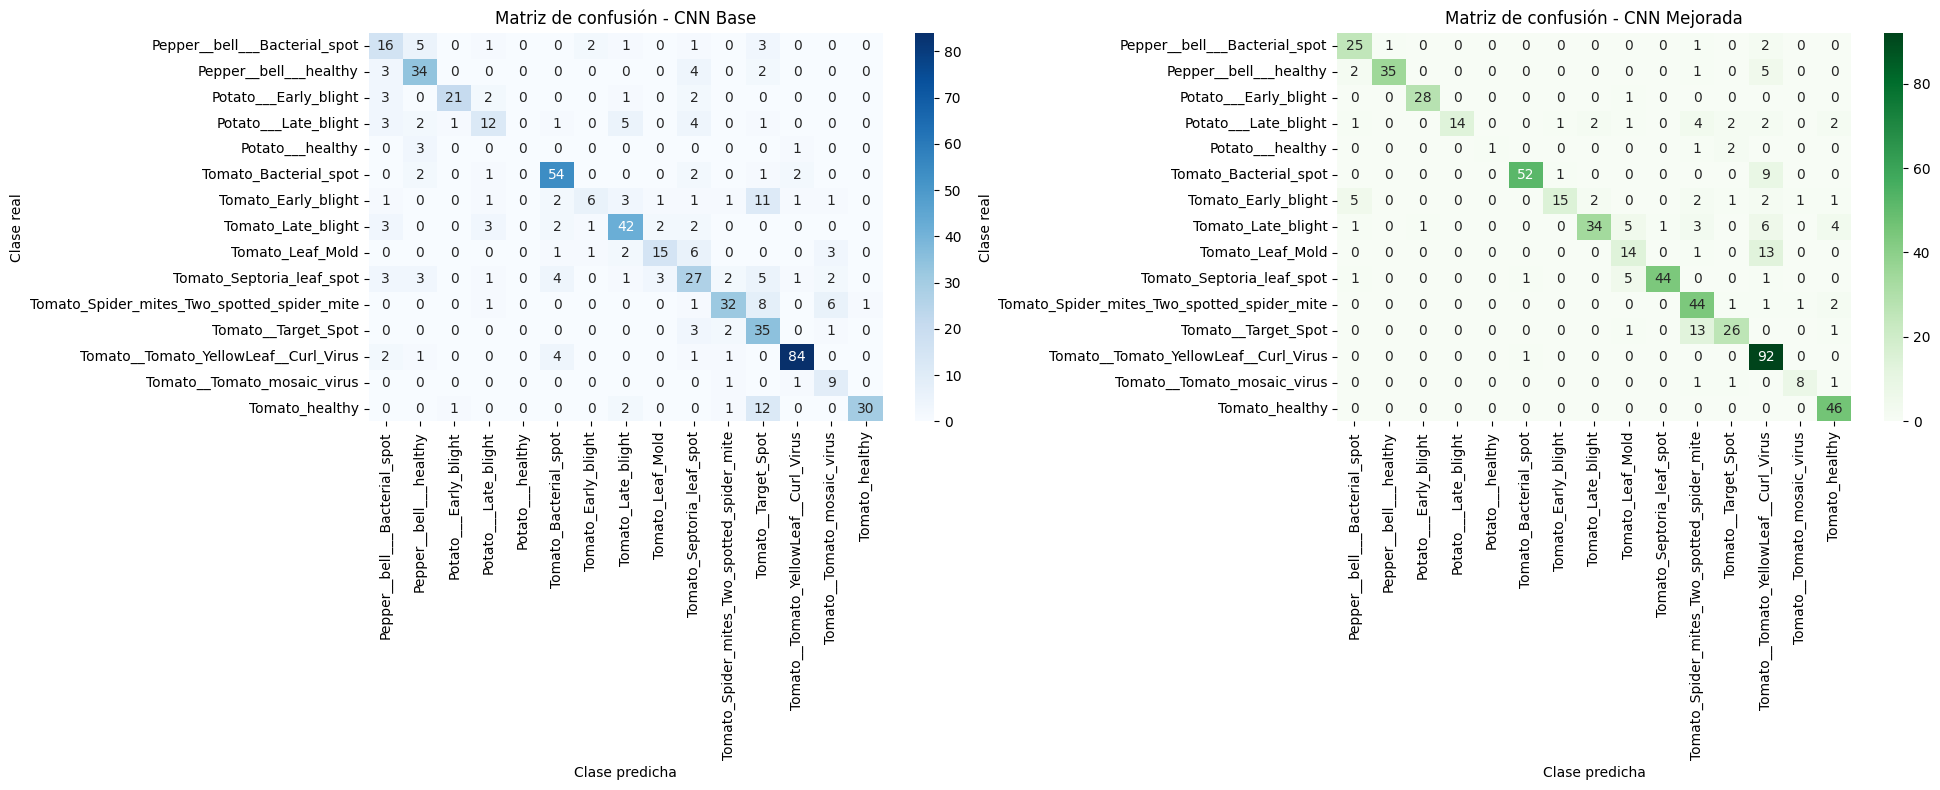

In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

#matrices de confusión
cm_base = confusion_matrix(
    y_test, y_pred_base, labels=range(len(class_names))
)

cm_cnn_2 = confusion_matrix(
    y_test, y_pred_cnn_2, labels=range(len(class_names))
)

#visualización
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    cm_base,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)
axes[0].set_title("Matriz de confusión - CNN Base")
axes[0].set_xlabel("Clase predicha")
axes[0].set_ylabel("Clase real")

sns.heatmap(
    cm_cnn_2,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)
axes[1].set_title("Matriz de confusión - CNN Mejorada")
axes[1].set_xlabel("Clase predicha")
axes[1].set_ylabel("Clase real")

plt.setp(axes[0].get_xticklabels(), rotation=90)
plt.setp(axes[1].get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()


### **7.3 Análisis de errores y comparación de modelos**

La segunda CNN presentó un mejor rendimiento general que la arquitectura base en las cuatro métricas evaluadas.

El accuracy aumentó de 69,50 % a 79,67 %, mientras que el F1-score macro pasó de 60,52 % a 75,24 %, evidenciando una mejora en el equilibrio entre precision y recall.

Al analizar las matrices de confusión, se observa que:

- La CNN base presenta dificultades para reconocer algunas clases, como `Potato___healthy`, que no obtuvo clasificaciones correctas, y `Tomato___Tomato_mosaic_virus`, con 9 aciertos.
- La CNN mejorada logra clasificar correctamente 92 imágenes de `Tomato___Tomato_YellowLeaf__Curl_Virus`, 52 de `Tomato_Bacterial_spot` y 46 de `Tomato_healthy`.
- Entre los errores de la segunda CNN destaca la confusión de 13 imágenes de `Tomato_Leaf_Mold` con `Tomato___Tomato_YellowLeaf__Curl_Virus`, además de 9 imágenes de `Tomato_Bacterial_spot` clasificadas como esta última clase.
- Aunque la segunda arquitectura mejora el rendimiento global, algunas clases continúan presentando dificultades, como `Potato___healthy`, que registra solo un acierto.

En general, la incorporación de una tercera capa convolucional, Batch Normalization, Dropout y regularización L2 permitió obtener mejores resultados en el conjunto de prueba. Sin embargo, las fluctuaciones observadas durante la validación indican que todavía existen oportunidades para mejorar la estabilidad del aprendizaje.

### **7.4 Comparación visual de métricas**

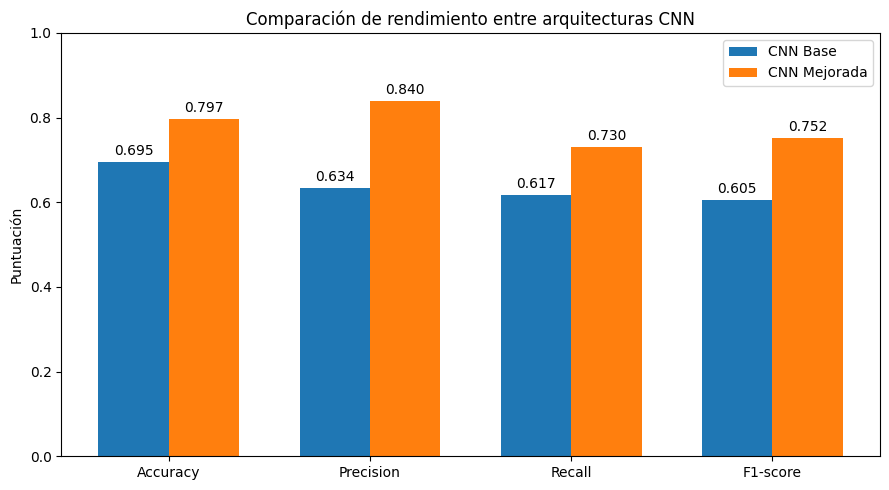

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

#comparación de métricas
metricas = resultados.columns.tolist()
valores_base = resultados.loc["CNN Base"].values
valores_mejorada = resultados.loc["CNN Mejorada"].values

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

barras_base = ax.bar(
    x - ancho/2,
    valores_base,
    ancho,
    label="CNN Base"
)

barras_mejorada = ax.bar(
    x + ancho/2,
    valores_mejorada,
    ancho,
    label="CNN Mejorada"
)

ax.set_title("Comparación de rendimiento entre arquitecturas CNN")
ax.set_ylabel("Puntuación")
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1)
ax.legend()

ax.bar_label(barras_base, fmt="%.3f", padding=3)
ax.bar_label(barras_mejorada, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


## **8. Conclusiones**



### **8.1 Principales resultados**

En este proyecto se desarrollaron y evaluaron dos arquitecturas de redes neuronales convolucionales (CNN) para clasificar enfermedades en hojas de plantas utilizando el dataset PlantVillage.

Se trabajó con una muestra de 4.200 imágenes distribuidas en 15 clases, utilizando 3.000 para entrenamiento, 600 para validación y 600 para prueba.

La CNN base obtuvo un accuracy de 69,50 % y un F1-score macro de 60,52 %, mientras que la segunda arquitectura alcanzó un accuracy de 79,67 % y un F1-score macro de 75,24 %.

Estos resultados representan una mejora de 10,17 puntos porcentuales en accuracy y 14,72 puntos porcentuales en F1-score macro.



### **8.2 Fortalezas y debilidades de las arquitecturas**

La CNN base presenta una arquitectura sencilla, con menor complejidad y un proceso de entrenamiento relativamente rápido. Sin embargo, mostró señales de sobreajuste y dificultades para clasificar correctamente determinadas enfermedades.

La segunda CNN incorporó una tercera capa convolucional, Batch Normalization, Dropout, regularización L2 y Global Average Pooling. Estas modificaciones permitieron obtener mejores resultados en el conjunto de prueba, demostrando una mayor capacidad de generalización respecto al modelo base.

No obstante, durante el entrenamiento se observaron fluctuaciones importantes en las métricas de validación, lo que evidencia cierta inestabilidad en el proceso de aprendizaje. Aunque la segunda arquitectura presentó un mejor rendimiento general, todavía existen oportunidades para mejorar la estabilidad de sus resultados.

### **8.3 Limitaciones del proyecto**

Una de las principales limitaciones fue utilizar una muestra de 4.200 imágenes en lugar del dataset completo, debido al tiempo y los recursos computacionales necesarios para el entrenamiento.

Además, las imágenes fueron redimensionadas a 64 × 64 píxeles, lo que podría provocar la pérdida de características visuales importantes para distinguir algunas enfermedades.

Las matrices de confusión también evidenciaron dificultades para diferenciar determinadas clases, especialmente aquellas que presentan características visuales similares.

Por otra parte, al utilizar imágenes del dataset PlantVillage, los resultados no garantizan el mismo rendimiento en fotografías tomadas en condiciones reales de cultivo.



### **8.4 Posibles mejoras futuras**

Como mejoras futuras, se propone ampliar la cantidad de imágenes utilizadas durante el entrenamiento e incorporar técnicas de aumento de datos (*Data Augmentation*) para mejorar la capacidad de generalización.

También sería conveniente experimentar con diferentes tasas de aprendizaje, tamaños de imagen y configuraciones de regularización.

Otra alternativa sería utilizar modelos preentrenados mediante *Transfer Learning*, como MobileNet o EfficientNet, y evaluar su rendimiento frente a las arquitecturas desarrolladas.

Finalmente, se recomienda validar los modelos con imágenes obtenidas en condiciones reales, considerando diferentes niveles de iluminación, fondos y estados de desarrollo de las enfermedades.



### **8.5 Conclusión general**

El desarrollo de esta evaluación permitió aplicar técnicas de Deep Learning para abordar un problema de clasificación de imágenes relacionado con enfermedades de plantas.

Los resultados demostraron que las modificaciones incorporadas en la segunda CNN permitieron mejorar el rendimiento respecto al modelo base, obteniendo mejores valores de accuracy, precision, recall y F1-score.

Sin embargo, también se identificaron limitaciones relacionadas con el tamaño de la muestra, la estabilidad del entrenamiento y la clasificación de determinadas enfermedades.

En conclusión, la segunda arquitectura presentó el mejor desempeño general en el conjunto de prueba, aunque todavía existen oportunidades de mejora para desarrollar un sistema de clasificación más robusto y aplicable a condiciones reales.